# EV Market Intelligence – Helper Notebook

This notebook is used to inspect, explore and test the datasets
before implementing calculations and visualizations in the Streamlit app.

In [44]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import plotly.express as px
import altair as alt

# Define project paths
PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "cleaned"

# Load datasets
ember_df = pd.read_csv(DATA_PATH / "ember_bev_clean.csv")
europe_df = pd.read_csv(DATA_PATH / "electric_vehicle_data.csv")

# Convert date column
ember_df["date"] = pd.to_datetime(ember_df["date"])

In [45]:
# ==========================================
# CHECK DATASET STRUCTURE
# ==========================================

print("MONTHLY BEV DATASET")
print("Shape:", ember_df.shape)
print("Columns:", ember_df.columns.tolist())

print("\nEUROPEAN EV INDICATORS DATASET")
print("Shape:", europe_df.shape)
print("Columns:", europe_df.columns.tolist())

MONTHLY BEV DATASET
Shape: (3630, 9)
Columns: ['country', 'country_code', 'date', 'bev_registrations', 'bev_share_pct', 'continent', 'ember_region', 'eu_member', 'year']

EUROPEAN EV INDICATORS DATASET
Shape: (311, 12)
Columns: ['country', 'country_code', 'year', 'bev_registrations', 'avg_monthly_bev_share_pct', 'months_available', 'charging_points', 'gdp_per_capita', 'population', 'electricity_price', 'electricity_periods', 'bev_registrations_per_1000_people']


## Geographical Coverage

Explore the countries and regions included in the monthly BEV dataset.
Identify the European countries and check the latest available reporting month.

In [46]:
# ==========================================
# CHECK GEOGRAPHICAL COVERAGE
# ==========================================

print("CONTINENTS")
print(ember_df["continent"].value_counts(dropna=False))

print("\nEMBER REGIONS")
print(ember_df["ember_region"].value_counts(dropna=False))

print("\nUNIQUE COUNTRIES")
print("Total countries:", ember_df["country"].nunique())

CONTINENTS
continent
Europe    3630
Name: count, dtype: int64

EMBER REGIONS
ember_region
Europe    3630
Name: count, dtype: int64

UNIQUE COUNTRIES
Total countries: 33


In [47]:
# ==========================================
# FILTER EUROPEAN COUNTRIES
# ==========================================

european_df = ember_df[ember_df["continent"] == "Europe"].copy()

print("European countries:", european_df["country"].nunique())
print("\nCountries included:")
print(sorted(european_df["country"].unique()))

European countries: 33

Countries included:
['Albania', 'Austria', 'Belgium', 'Bulgaria', 'Croatia', 'Cyprus', 'Czechia', 'Denmark', 'Estonia', 'Finland', 'France', 'Germany', 'Greece', 'Hungary', 'Iceland', 'Ireland', 'Italy', 'Latvia', 'Lithuania', 'Luxembourg', 'Malta', 'Netherlands', 'Norway', 'Poland', 'Portugal', 'Romania', 'Slovakia', 'Slovenia', 'Spain', 'Sweden', 'Switzerland', 'Ukraine', 'United Kingdom']


In [48]:
# ==========================================
# CHECK DATE COVERAGE
# ==========================================

print("First available month:", european_df["date"].min().strftime("%B %Y"))

print("Latest available month:", european_df["date"].max().strftime("%B %Y"))

print("\nLatest reporting month by country:")

print(european_df.groupby("country")["date"].max().sort_values(ascending=False))

First available month: January 2005
Latest available month: October 2026

Latest reporting month by country:
country
Portugal         2026-10-01
Norway           2026-10-01
Germany          2026-10-01
Netherlands      2026-10-01
Albania          2026-09-01
Latvia           2026-09-01
Switzerland      2026-09-01
Sweden           2026-09-01
Spain            2026-09-01
Slovenia         2026-09-01
Slovakia         2026-09-01
Romania          2026-09-01
Poland           2026-09-01
Malta            2026-09-01
Luxembourg       2026-09-01
Lithuania        2026-09-01
Italy            2026-09-01
Austria          2026-09-01
Ireland          2026-09-01
Iceland          2026-09-01
Hungary          2026-09-01
Greece           2026-09-01
France           2026-09-01
Finland          2026-09-01
Estonia          2026-09-01
Denmark          2026-09-01
Czechia          2026-09-01
Cyprus           2026-09-01
Croatia          2026-09-01
Bulgaria         2026-09-01
Belgium          2026-09-01
United Kingdom 

## European EV Market Overview – Key Metrics

Calculate key indicators to summarize the current state of BEV adoption
across European countries.

September 2026 is used as the common reporting month to ensure
comparability between countries.

In [49]:
# ==========================================
# SEPTEMBER 2026 EUROPEAN SNAPSHOT
# ==========================================

snapshot_date = "2026-09-01"

europe_snapshot = european_df[european_df["date"] == snapshot_date].copy()

print("Countries included:", europe_snapshot["country"].nunique())
print("Total BEV registrations:", europe_snapshot["bev_registrations"].sum())

print("Average BEV market share:", europe_snapshot["bev_share_pct"].mean())

print("Median BEV market share:", europe_snapshot["bev_share_pct"].median())

Countries included: 32
Total BEV registrations: 418309.0
Average BEV market share: 31.8509375
Median BEV market share: 25.73


In [50]:
# ==========================================
# INSPECT SEPTEMBER 2026 DATA
# ==========================================

europe_snapshot[["country", "bev_registrations", "bev_share_pct"]].sort_values(
    "bev_share_pct", ascending=False
)

,country,bev_registrations,bev_share_pct
2379,Norway,18511.0,98.81
778,Denmark,17778.0,88.61
1346,Iceland,771.0,81.59
952,Finland,4338.0,62.11
2117,Netherlands,19052.0,52.81
362,Belgium,16341.0,50.87
1583,Ireland,3116.0,49.29
2578,Portugal,9338.0,48.05
3104,Sweden,14096.0,47.22
2012,Malta,283.0,44.99


## Top 10 European Countries by BEV Market Share

Compare BEV market share across the ten leading European countries
in September 2026.

In [51]:
# ==========================================
# TOP 10 COUNTRIES BY BEV MARKET SHARE
# ==========================================

top_10_share = europe_snapshot.sort_values("bev_share_pct", ascending=False).head(10)

top_10_share[["country", "bev_share_pct"]]

,country,bev_share_pct
2379,Norway,98.81
778,Denmark,88.61
1346,Iceland,81.59
952,Finland,62.11
2117,Netherlands,52.81
362,Belgium,50.87
1583,Ireland,49.29
2578,Portugal,48.05
3104,Sweden,47.22
2012,Malta,44.99


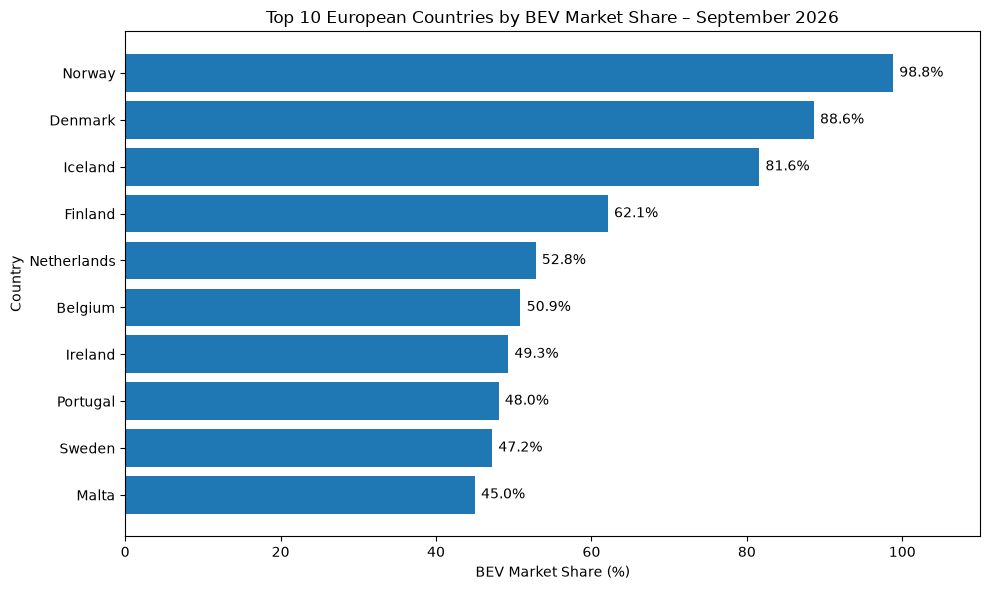

In [52]:
# ==========================================
# VISUALIZE TOP 10 COUNTRIES
# ==========================================

plt.figure(figsize=(10, 6))

bars = plt.barh(top_10_share["country"], top_10_share["bev_share_pct"])

# Add percentage labels
for bar in bars:
    plt.text(
        bar.get_width() + 0.8,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.1f}%",
        va="center",
    )

plt.xlabel("BEV Market Share (%)")
plt.ylabel("Country")
plt.title("Top 10 European Countries by BEV Market Share – September 2026")

plt.xlim(0, 110)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## Historical European BEV Market Share

Analyze how average BEV market share has evolved across European
countries over time.

The monthly average is calculated using only countries with
available data for each month.

In [53]:
# ==========================================
# CALCULATE MONTHLY EUROPEAN BEV MARKET SHARE
# ==========================================

# Group monthly data by date and calculate the average
europe_monthly_trend = (
    european_df.groupby("date")
    .agg(
        average_bev_share=("bev_share_pct", "mean"),
        countries_reporting=("country", "nunique"),
    )
    .reset_index()
)

# Inspect the results
europe_monthly_trend.head()

,date,average_bev_share,countries_reporting
0,2005-01-01,0.015,2
1,2005-02-01,0.010,2
2,2005-03-01,0.005,2
3,2005-04-01,0.005,2
4,2005-05-01,0.000,2


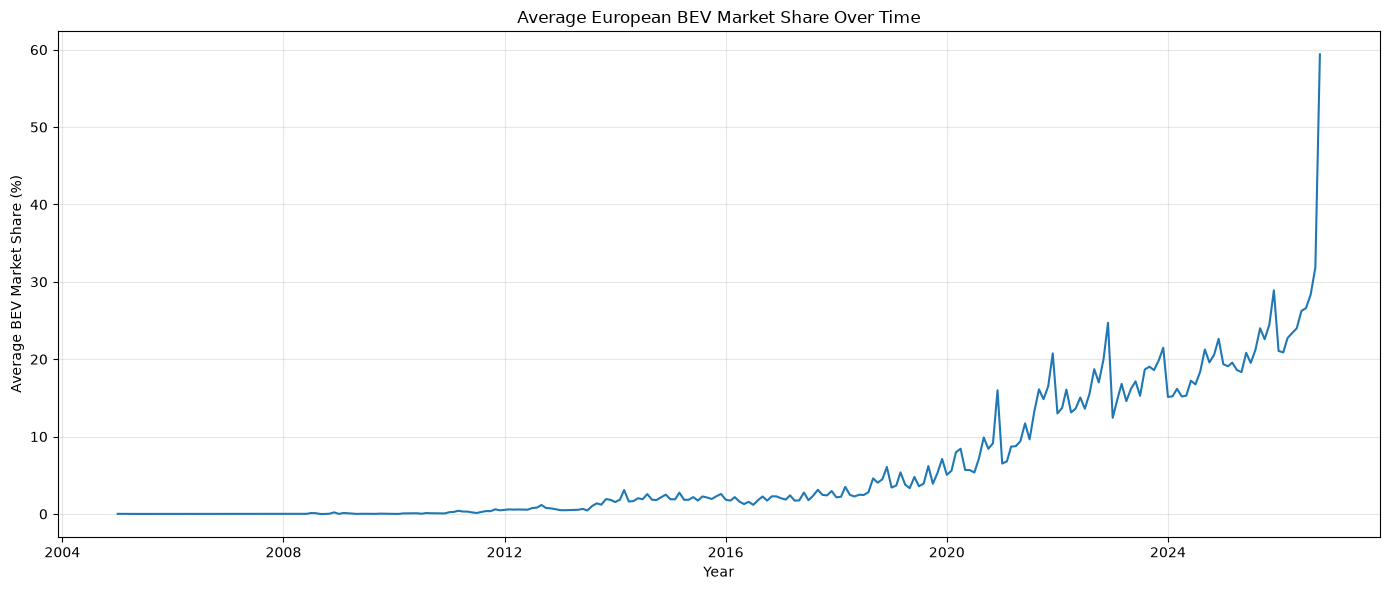

In [54]:
# ==========================================
# VISUALIZE HISTORICAL EUROPEAN BEV ADOPTION
# ==========================================

plt.figure(figsize=(14, 6))

plt.plot(europe_monthly_trend["date"], europe_monthly_trend["average_bev_share"])

plt.xlabel("Year")
plt.ylabel("Average BEV Market Share (%)")
plt.title("Average European BEV Market Share Over Time")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [55]:
# ==========================================
# INVESTIGATE MONTHLY DATA COVERAGE
# ==========================================

# Inspect the latest 18 months
europe_monthly_trend.tail(18)

,date,average_bev_share,countries_reporting
244,2025-05-01,18.336667,33
245,2025-06-01,20.827273,33
246,2025-07-01,19.525152,33
247,2025-08-01,21.195758,33
248,2025-09-01,24.000000,33
249,2025-10-01,22.582727,33
250,2025-11-01,24.463939,33
251,2025-12-01,28.896970,33
252,2026-01-01,21.066364,33
253,2026-02-01,20.879091,33


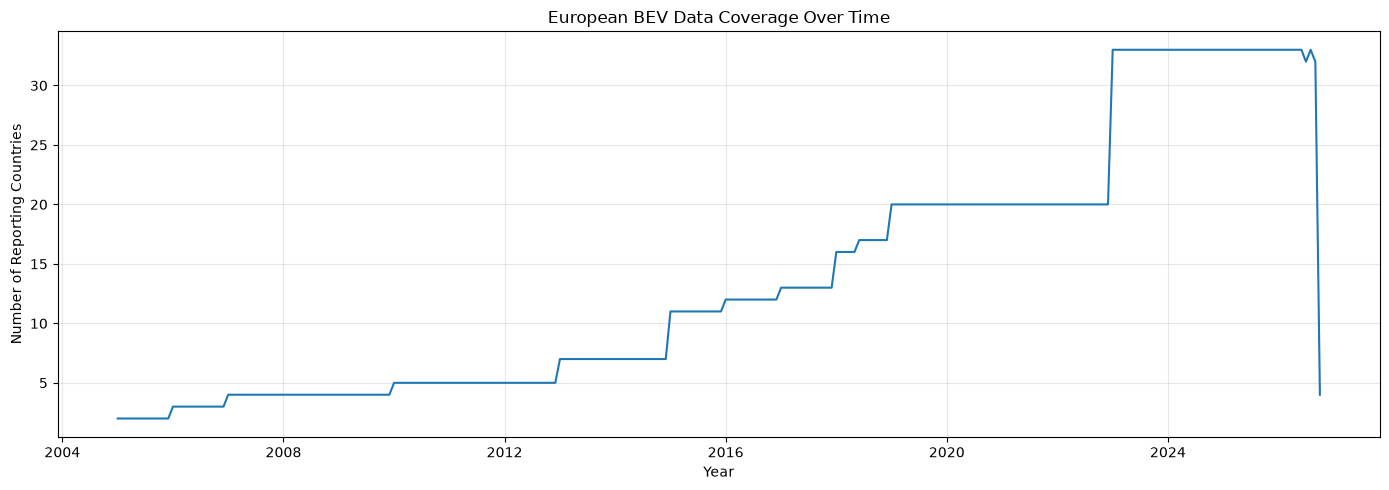

In [24]:
# ==========================================
# VISUALIZE NUMBER OF REPORTING COUNTRIES
# ==========================================

plt.figure(figsize=(14, 5))

plt.plot(europe_monthly_trend["date"], europe_monthly_trend["countries_reporting"])

plt.xlabel("Year")
plt.ylabel("Number of Reporting Countries")
plt.title("European BEV Data Coverage Over Time")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## European BEV Adoption Trend – 2023 to 2026

Focus on the period from January 2023 to September 2026,
when the dataset provides broad coverage of European countries.

October 2026 is excluded because only four countries have
reported data for this month.

In [25]:
# ==========================================
# FILTER HISTORICAL DATA
# ==========================================

# Define the analysis period
start_date = "2023-01-01"
end_date = "2026-09-01"

# Filter the monthly trend
europe_monthly_trend_recent = europe_monthly_trend[
    (europe_monthly_trend["date"] >= start_date)
    & (europe_monthly_trend["date"] <= end_date)
].copy()

# Inspect the results
print(
    "Period:",
    europe_monthly_trend_recent["date"].min(),
    "to",
    europe_monthly_trend_recent["date"].max(),
)

print(
    "Minimum countries reporting:",
    europe_monthly_trend_recent["countries_reporting"].min(),
)

print(
    "Maximum countries reporting:",
    europe_monthly_trend_recent["countries_reporting"].max(),
)

Period: 2023-01-01 00:00:00 to 2026-09-01 00:00:00
Minimum countries reporting: 32
Maximum countries reporting: 33


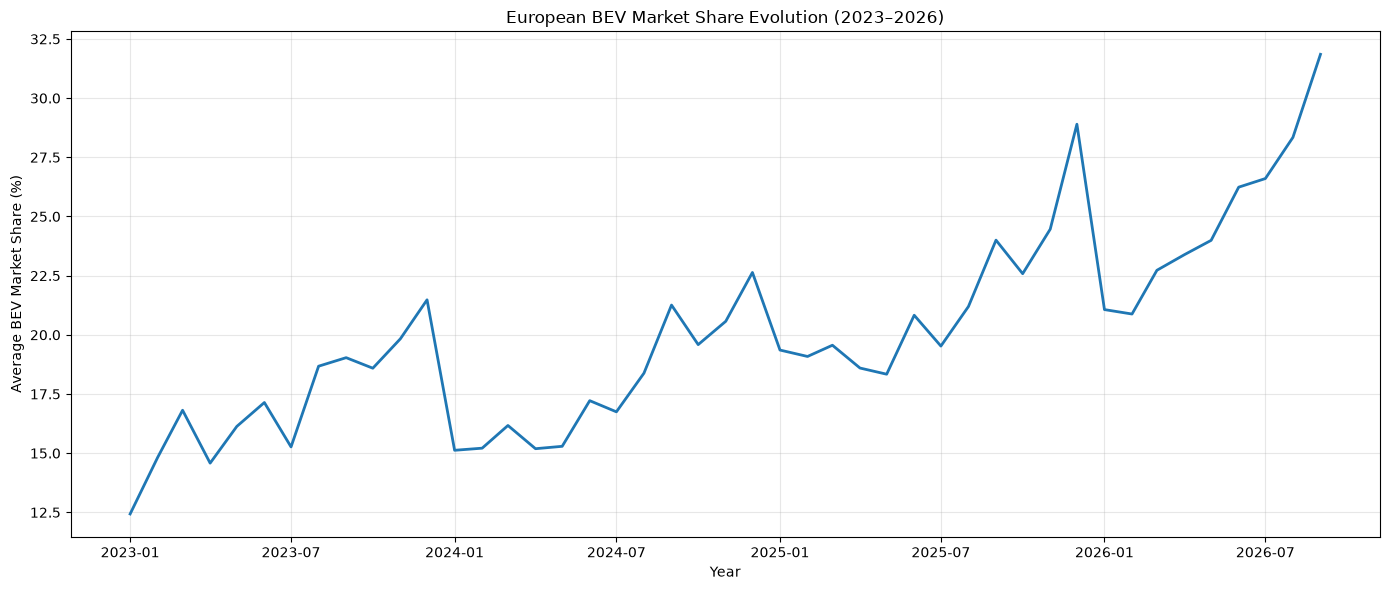

In [26]:
# ==========================================
# VISUALIZE RECENT EUROPEAN BEV ADOPTION
# ==========================================

plt.figure(figsize=(14, 6))

plt.plot(
    europe_monthly_trend_recent["date"],
    europe_monthly_trend_recent["average_bev_share"],
    linewidth=2,
)

plt.xlabel("Year")
plt.ylabel("Average BEV Market Share (%)")
plt.title("European BEV Market Share Evolution (2023–2026)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [27]:
# ==========================================
# INVESTIGATE UKRAINE'S BEV MARKET SHARE
# ==========================================

ukraine_check = ember_df[
    (ember_df["country"] == "Ukraine")
    & (ember_df["date"] >= "2025-07-01")
    & (ember_df["date"] <= "2026-05-01")
][["country", "date", "bev_registrations", "bev_share_pct"]].sort_values("date")

ukraine_check

,country,date,bev_registrations,bev_share_pct
3516,Ukraine,2025-07-01,6811.0,23.46
3517,Ukraine,2025-08-01,7726.0,26.02
3518,Ukraine,2025-09-01,8764.0,29.35
3519,Ukraine,2025-10-01,10205.0,29.87
3520,Ukraine,2025-11-01,10459.0,33.68
3521,Ukraine,2025-12-01,30327.0,58.31
3522,Ukraine,2026-01-01,2265.0,10.44
3523,Ukraine,2026-02-01,981.0,5.12
3524,Ukraine,2026-03-01,1926.0,7.92
3525,Ukraine,2026-04-01,2826.0,10.91


In [28]:
# Check country codes for the map
print(ember_df[["country", "country_code"]].drop_duplicates().head(15))

       country country_code
0      Albania          ALB
93     Austria          AUT
198    Belgium          BEL
363   Bulgaria          BGR
407    Croatia          HRV
452     Cyprus          CYP
497    Czechia          CZE
638    Denmark          DNK
779    Estonia          EST
824    Finland          FIN
953     France          FRA
1094   Germany          DEU
1212    Greece          GRC
1257   Hungary          HUN
1302   Iceland          ISL


## Interactive European BEV Adoption Map

Visualize BEV market share across European countries in September 2026.

Each country is represented by its ISO-3 country code.

In [29]:
# ==========================================
# PREPARE DATA FOR EUROPEAN BEV MAP
# ==========================================

# Select September 2026 data
map_data = europe_snapshot[
    ["country", "country_code", "bev_registrations", "bev_share_pct"]
].copy()

# Inspect the map data
map_data = map_data.sort_values("bev_share_pct", ascending=False)

map_data.head(10)

,country,country_code,bev_registrations,bev_share_pct
2379,Norway,NOR,18511.0,98.81
778,Denmark,DNK,17778.0,88.61
1346,Iceland,ISL,771.0,81.59
952,Finland,FIN,4338.0,62.11
2117,Netherlands,NLD,19052.0,52.81
362,Belgium,BEL,16341.0,50.87
1583,Ireland,IRL,3116.0,49.29
2578,Portugal,PRT,9338.0,48.05
3104,Sweden,SWE,14096.0,47.22
2012,Malta,MLT,283.0,44.99


In [30]:
# ==========================================
# CREATE INTERACTIVE EUROPEAN BEV MAP
# ==========================================

fig = px.choropleth(
    map_data,
    locations="country_code",
    locationmode="ISO-3",
    color="bev_share_pct",
    hover_name="country",
    hover_data={
        "country_code": False,
        "bev_registrations": ":,.0f",
        "bev_share_pct": ":.2f",
    },
    color_continuous_scale="Blues",
    range_color=(0, 100),
    scope="europe",
    title="BEV Market Share Across Europe – September 2026",
    labels={
        "bev_registrations": "BEV Registrations",
        "bev_share_pct": "BEV Market Share (%)",
        "country_code": "Country Code",
    },
)

# ==========================================
# IMPROVE MAP LAYOUT
# ==========================================

fig.update_layout(
    height=520,
    margin={"r": 30, "t": 80, "l": 20, "b": 20},
    coloraxis_colorbar={"title": "BEV Market Share (%)", "len": 0.75, "thickness": 18},
)

# Zoom to the countries represented in the dataset
fig.update_geos(fitbounds="locations", visible=True)

fig.show()

## Adoption Drivers Navigation Section

In [31]:
# Inspect the European indicators dataset

print("Dataset shape:", europe_df.shape)

display(europe_df.head())

print("\nMissing values:")
display(europe_df.isna().sum())

print("\nYear range:")
print(europe_df["year"].min(), "-", europe_df["year"].max())

print("\nCountries:", europe_df["country"].nunique())

Dataset shape: (311, 12)


,country,country_code,year,bev_registrations,avg_monthly_bev_share_pct,months_available,charging_points,gdp_per_capita,population,electricity_price,electricity_periods,bev_registrations_per_1000_people
0,Albania,ALB,2019,24.0,0.063333,12,NaN,4850.0,2862427.0,0.09265,2.0,0.008384
1,Albania,ALB,2020,239.0,0.573333,12,NaN,4710.0,2845955.0,0.09210,2.0,0.083979
2,Albania,ALB,2021,262.0,0.477500,12,NaN,5190.0,2829741.0,0.09310,2.0,0.092588
3,Albania,ALB,2022,624.0,1.251667,12,NaN,5500.0,2793592.0,0.09585,2.0,0.223368
4,Albania,ALB,2023,1671.0,2.505833,12,NaN,NaN,2761785.0,0.10495,2.0,0.605043



Missing values:


country                                0
country_code                           0
year                                   0
bev_registrations                      0
avg_monthly_bev_share_pct              0
months_available                       0
charging_points                      193
gdp_per_capita                        57
population                            51
electricity_price                     39
electricity_periods                   39
bev_registrations_per_1000_people     51
dtype: int64


Year range:
2005 - 2026

Countries: 33


In [32]:
# Check data availability for each adoption driver

indicators = [
    "avg_monthly_bev_share_pct",
    "gdp_per_capita",
    "charging_points",
    "electricity_price",
    "population",
]

print("Available observations:")
display(europe_df[indicators].count())

print("\nMissing values (%):")
display((europe_df[indicators].isna().mean() * 100).round(1))

print("\nMonths available per year:")
display(
    europe_df.groupby("year")["months_available"].agg(["min", "max", "mean"]).tail(5)
)

Available observations:


avg_monthly_bev_share_pct    311
gdp_per_capita               254
charging_points              118
electricity_price            272
population                   260
dtype: int64


Missing values (%):


avg_monthly_bev_share_pct     0.0
gdp_per_capita               18.3
charging_points              62.1
electricity_price            12.5
population                   16.4
dtype: float64


Months available per year:


,min,max,mean
year,,,
2022,12,12,12.000000
2023,12,12,12.000000
2024,12,12,12.000000
2025,12,12,12.000000
2026,8,10,9.060606


In [33]:
# Prepare data for GDP vs BEV market share analysis

gdp_df = (
    europe_df[(europe_df["year"] >= 2015) & (europe_df["year"] <= 2025)]
    .dropna(subset=["gdp_per_capita", "avg_monthly_bev_share_pct"])
    .copy()
)

print("Observations:", len(gdp_df))
print("Countries:", gdp_df["country"].nunique())

display(gdp_df.head())

Observations: 210
Countries: 31


,country,country_code,year,bev_registrations,avg_monthly_bev_share_pct,months_available,charging_points,gdp_per_capita,population,electricity_price,electricity_periods,bev_registrations_per_1000_people
0,Albania,ALB,2019,24.0,0.063333,12,NaN,4850.0,2862427.0,0.09265,2.0,0.008384
1,Albania,ALB,2020,239.0,0.573333,12,NaN,4710.0,2845955.0,0.09210,2.0,0.083979
2,Albania,ALB,2021,262.0,0.477500,12,NaN,5190.0,2829741.0,0.09310,2.0,0.092588
3,Albania,ALB,2022,624.0,1.251667,12,NaN,5500.0,2793592.0,0.09585,2.0,0.223368
8,Austria,AUT,2018,6757.0,2.146667,12,NaN,45140.0,8822267.0,0.19890,2.0,0.765903


In [34]:
# Calculate Pearson correlation

correlation = gdp_df[["gdp_per_capita", "avg_monthly_bev_share_pct"]].corr().iloc[0, 1]

print("GDP vs BEV market share correlation:", round(correlation, 3))

GDP vs BEV market share correlation: 0.33


In [35]:
# Visualise GDP per capita vs BEV market share

gdp_chart = (
    alt.Chart(gdp_df)
    .mark_circle(size=80, opacity=0.65)
    .encode(
        x=alt.X("gdp_per_capita:Q", title="GDP per capita"),
        y=alt.Y("avg_monthly_bev_share_pct:Q", title="BEV market share (%)"),
        color=alt.Color("year:O", title="Year"),
        tooltip=["country", "year", "gdp_per_capita", "avg_monthly_bev_share_pct"],
    )
    .properties(title="GDP per Capita vs BEV Market Share", width=700, height=450)
)

gdp_chart.show()

alt.Chart(...)

In [36]:
# Investigate unusual countries in 2025

gdp_2025 = gdp_df[gdp_df["year"] == 2025].copy()

# Countries with the highest BEV market share
print("TOP 10 COUNTRIES - BEV MARKET SHARE")
display(
    gdp_2025.sort_values("avg_monthly_bev_share_pct", ascending=False)[
        ["country", "gdp_per_capita", "avg_monthly_bev_share_pct"]
    ].head(10)
)

# Identify high-GDP countries with relatively low BEV adoption

print("HIGH-GDP COUNTRIES WITH LOWEST BEV MARKET SHARE")

high_gdp_countries = gdp_2025[
    gdp_2025["gdp_per_capita"] >= gdp_2025["gdp_per_capita"].median()
]

display(
    high_gdp_countries.sort_values("avg_monthly_bev_share_pct", ascending=True)[
        ["country", "gdp_per_capita", "avg_monthly_bev_share_pct"]
    ].head(10)
)

TOP 10 COUNTRIES - BEV MARKET SHARE


,country,gdp_per_capita,avg_monthly_bev_share_pct
202,Norway,66720.0,95.586667
65,Denmark,60390.0,67.933333
114,Iceland,59430.0,44.015833
180,Netherlands,51400.0,39.590000
80,Finland,43470.0,37.311667
264,Sweden,49250.0,35.225000
29,Belgium,44550.0,35.010000
134,Ireland,94930.0,28.780000
167,Luxembourg,102840.0,27.095000
171,Malta,34360.0,26.835833


HIGH-GDP COUNTRIES WITH LOWEST BEV MARKET SHARE


,country,gdp_per_capita,avg_monthly_bev_share_pct
142,Italy,33260.0,6.240000
102,Germany,43750.0,19.026667
92,France,38360.0,19.734167
15,Austria,45580.0,21.210000
286,Switzerland,83000.0,22.380000
171,Malta,34360.0,26.835833
167,Luxembourg,102840.0,27.095000
134,Ireland,94930.0,28.780000
29,Belgium,44550.0,35.010000
264,Sweden,49250.0,35.225000


In [37]:
# Calculate GDP vs BEV market share correlation for 2025

gdp_2025_correlation = (
    gdp_2025[["gdp_per_capita", "avg_monthly_bev_share_pct"]].corr().iloc[0, 1]
)

print("GDP vs BEV market share correlation (2025):", round(gdp_2025_correlation, 3))

GDP vs BEV market share correlation (2025): 0.605


In [38]:
# Prepare data for charging infrastructure analysis

charging_df = (
    europe_df[(europe_df["year"] >= 2015) & (europe_df["year"] <= 2025)]
    .dropna(subset=["charging_points", "population", "avg_monthly_bev_share_pct"])
    .copy()
)

# Calculate charging points per 100,000 inhabitants

charging_df["charging_points_per_100k"] = (
    charging_df["charging_points"] / charging_df["population"]
) * 100000

print("Available observations:", len(charging_df))
print("Countries:", charging_df["country"].nunique())

display(
    charging_df[
        [
            "country",
            "year",
            "charging_points",
            "population",
            "charging_points_per_100k",
            "avg_monthly_bev_share_pct",
        ]
    ].head(10)
)

Available observations: 118
Countries: 30


,country,year,charging_points,population,charging_points_per_100k,avg_monthly_bev_share_pct
11,Austria,2021,9143.0,8932664.0,102.354684,14.203333
12,Austria,2022,14526.0,8978929.0,161.778760,15.743333
13,Austria,2023,19663.0,9104772.0,215.963673,19.944167
14,Austria,2024,25632.0,9158750.0,279.863518,17.656667
15,Austria,2025,34333.0,9197213.0,373.297868,21.210000
26,Belgium,2022,27000.0,11617623.0,232.405545,10.375833
27,Belgium,2023,43470.0,11742796.0,370.184409,19.900000
28,Belgium,2024,111500.0,11817096.0,943.548229,29.275000
29,Belgium,2025,106500.0,11883495.0,896.200991,35.010000
31,Bulgaria,2023,1624.0,6447710.0,25.187237,4.004167


In [39]:
# Calculate charging infrastructure vs BEV market share correlation

charging_correlation = (
    charging_df[["charging_points_per_100k", "avg_monthly_bev_share_pct"]]
    .corr()
    .iloc[0, 1]
)

print(
    "Charging infrastructure vs BEV market share correlation:",
    round(charging_correlation, 3),
)

Charging infrastructure vs BEV market share correlation: 0.669


In [40]:
# Investigate unusual charging infrastructure patterns

charging_2025 = charging_df[
    charging_df["year"] == 2025
].copy()

# Countries with the most charging points per 100k inhabitants
print("TOP 10 COUNTRIES - CHARGING INFRASTRUCTURE")

display(
    charging_2025.sort_values(
        "charging_points_per_100k",
        ascending=False
    )[
        [
            "country",
            "charging_points_per_100k",
            "avg_monthly_bev_share_pct"
        ]
    ].head(10)
)

# Countries with high BEV adoption but relatively little infrastructure
print("HIGH BEV ADOPTION - LOWER CHARGING INFRASTRUCTURE")

display(
    charging_2025.sort_values(
        "avg_monthly_bev_share_pct",
        ascending=False
    )[
        [
            "country",
            "charging_points_per_100k",
            "avg_monthly_bev_share_pct"
        ]
    ].head(10)
)

TOP 10 COUNTRIES - CHARGING INFRASTRUCTURE


,country,charging_points_per_100k,avg_monthly_bev_share_pct
180,Netherlands,1161.121073,39.590000
29,Belgium,896.200991,35.010000
65,Denmark,839.983887,67.933333
114,Iceland,753.895297,44.015833
264,Sweden,590.769864,35.225000
202,Norway,567.394903,95.586667
167,Luxembourg,542.690106,27.095000
15,Austria,373.297868,21.210000
80,Finland,357.276501,37.311667
92,France,269.300230,19.734167


HIGH BEV ADOPTION - LOWER CHARGING INFRASTRUCTURE


,country,charging_points_per_100k,avg_monthly_bev_share_pct
202,Norway,567.394903,95.586667
65,Denmark,839.983887,67.933333
114,Iceland,753.895297,44.015833
180,Netherlands,1161.121073,39.590000
80,Finland,357.276501,37.311667
264,Sweden,590.769864,35.225000
29,Belgium,896.200991,35.010000
134,Ireland,62.790909,28.780000
167,Luxembourg,542.690106,27.095000
171,Malta,78.711363,26.835833


In [41]:
# Visualise the relationship between charging infrastructure
# and BEV market share in 2025

charging_scatter = alt.Chart(charging_2025).mark_circle(
    size=100
).encode(
    x=alt.X(
        "charging_points_per_100k:Q",
        title="Charging points per 100,000 inhabitants"
    ),
    y=alt.Y(
        "avg_monthly_bev_share_pct:Q",
        title="BEV share of new registrations (%)"
    ),
    tooltip=[
        "country",
        "charging_points_per_100k",
        "avg_monthly_bev_share_pct"
    ]
).properties(
    title="Charging Infrastructure vs BEV Adoption (2025)",
    width=650,
    height=400
)

display(charging_scatter)

alt.Chart(...)

## Future Forecasts Navigation Section

In [43]:
# List all variables currently available in the helper notebook
%whos

Variable                      Type            Data/Info
-------------------------------------------------------
DATA_PATH                     WindowsPath     c:\Ironhack Data Analysis<...>tion_project\data\cleaned
PROJECT_ROOT                  WindowsPath     c:\Ironhack Data Analysis<...>nit_8\ev_adoption_project
Path                          type            <class 'pathlib.Path'>
alt                           module          <module 'altair' from 'c:<...>es\\altair\\__init__.py'>
bar                           Rectangle       Rectangle(xy=(0, 8.6), wi<...>.99, height=0.8, angle=0)
bars                          BarContainer    <BarContainer object of 10 artists>
charging_2025                 DataFrame       Shape: (29, 13)
charging_correlation          float64         0.6687671493792063
charging_df                   DataFrame       Shape: (118, 13)
charging_scatter              Chart           alt.Chart(...)
correlation                   float64         0.33012289897864794
ember_df    